# 03 · Morphology and connected components

**Level:** beginner to intermediate. **Time:** 45–60 minutes. **Prerequisites:** Boolean masks and notebook 02 concepts. Run independently with **Restart Kernel → Run All**.

**You will:** repair a damaged mask; explain erosion, dilation, opening, and closing; label connected objects; measure their areas and boxes; see why connectivity and border policy matter. All data are generated locally with a fixed seed.

**Question to keep asking:** am I removing measurement noise, or erasing a real small object?


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "learning" / "data.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete ImageSegmentationPractical folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.5), "image.cmap": "gray",
                     "axes.spines.top": False, "axes.spines.right": False})
print("Project:", PROJECT_ROOT.name)


Project: ImageSegmentationPractical


## 1. Construct damaged foreground

There are three intended objects, including one smaller disk. The noisy observation contains extra pixels and a small hole. The ideal binary mask is known only because this is a controlled simulation. In real data, a postprocessing rule needs validation against trusted annotations.


In [2]:
from scipy import ndimage as ndi
from skimage import morphology, measure, color, segmentation
import pandas as pd

yy, xx = np.mgrid[:128, :160]
truth = ((yy - 38)**2 + (xx - 38)**2 <= 21**2)
truth |= ((yy - 93)**2 + (xx - 42)**2 <= 9**2)
truth[43:93, 92:140] = True
rng = np.random.default_rng(12)
damaged = truth.copy()
damaged[rng.random(truth.shape) < 0.012] = True
damaged[32:38, 34:40] = False
damaged[61:64, 92:103] = False
print("Boolean mask:", damaged.dtype, "foreground pixels:", damaged.sum())

def show_grid(images, titles, columns=3, cmap="gray", limits=None):
    """A small display helper; every array is still available for inspection."""
    rows = (len(images) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 3.4 * rows), squeeze=False)
    for ax, image, title in zip(axes.flat, images, titles):
        kwargs = {} if limits is None else {"vmin": limits[0], "vmax": limits[1]}
        ax.imshow(image, cmap=cmap, **kwargs)
        ax.set_title(title)
        ax.axis("off")
    for ax in list(axes.flat)[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


Boolean mask: bool foreground pixels: 4170


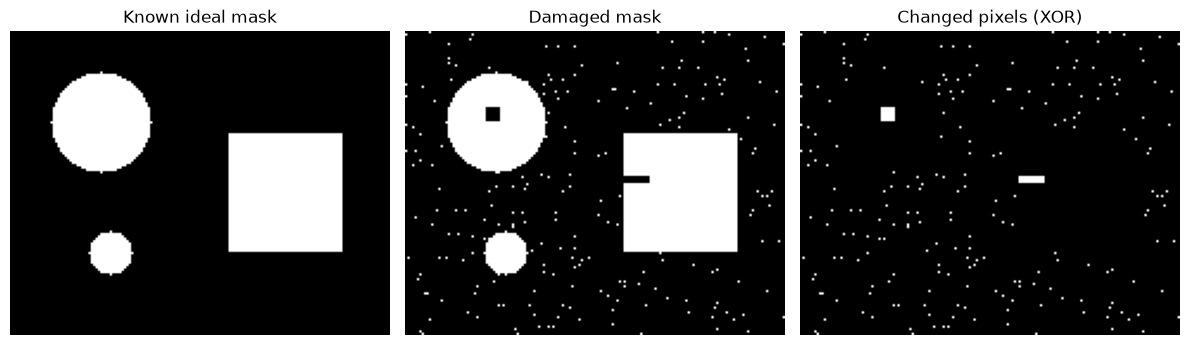

In [3]:
show_grid([truth, damaged, damaged ^ truth],
          ["Known ideal mask", "Damaged mask", "Changed pixels (XOR)"])


## 2. A footprint defines the neighborhood

Imagine moving a small disk over the mask. **Erosion** keeps a foreground pixel only when the footprint fits inside foreground. **Dilation** adds pixels reached by the footprint. Both change object boundaries. The radius is measured in pixels, so resizing an image changes its physical meaning.

**Predict:** which operation is likely to break a narrow bridge? Which can connect nearby objects?


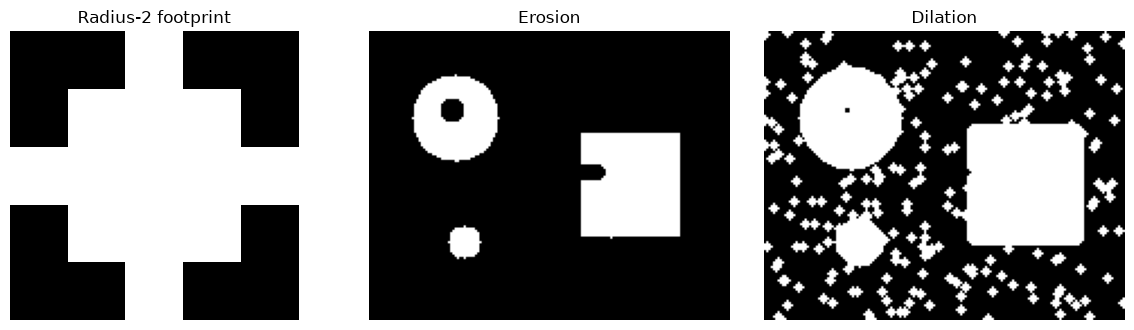

Before / eroded / dilated pixel counts: 4170 3174 7181


In [4]:
footprint = morphology.disk(2)
eroded = morphology.erosion(damaged, footprint)
dilated = morphology.dilation(damaged, footprint)
show_grid([footprint, eroded, dilated], ["Radius-2 footprint", "Erosion", "Dilation"])
print("Before / eroded / dilated pixel counts:", damaged.sum(), eroded.sum(), dilated.sum())


## 3. Compose operations to clean the mask

**Opening = erosion then dilation**; it suppresses features too narrow to hold the footprint. **Closing = dilation then erosion**; it can seal narrow gaps. Neither operation knows whether a thin detail is important.

`binary_fill_holes` fills every enclosed background region. A hollow object may contain a meaningful cavity, so use that step only when the object definition calls for a solid region.


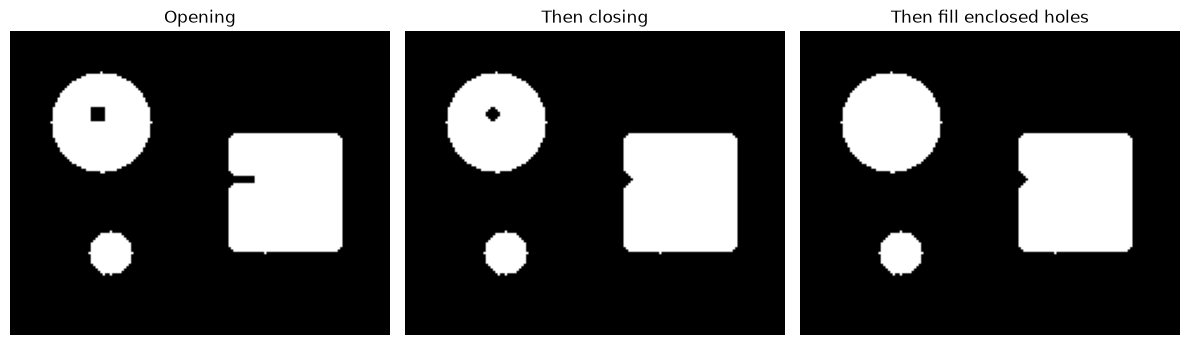

Removed by opening: 228
Added by hole filling: 24


In [5]:
opened = morphology.opening(damaged, footprint)
closed = morphology.closing(opened, footprint)
filled = ndi.binary_fill_holes(closed)
show_grid([opened, closed, filled], ["Opening", "Then closing", "Then fill enclosed holes"])
print("Removed by opening:", int((damaged & ~opened).sum()))
print("Added by hole filling:", int((filled & ~closed).sum()))


## 4. Connectivity changes the object count

In 2D, connectivity 1 uses four edge-sharing neighbors. Connectivity 2 also includes four diagonal neighbors. Two diagonal pixels are two components under the first rule, one under the second. Labels are **object IDs**: label 2 is not twice as much foreground as label 1.


4-neighbor components: 5
8-neighbor components: 1


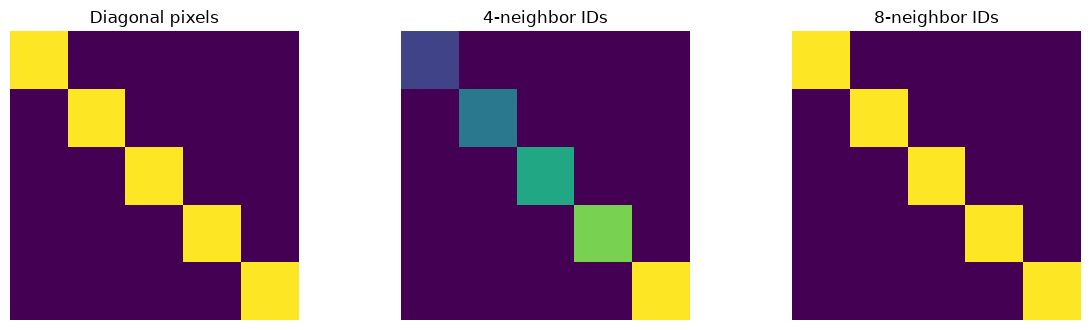

In [6]:
diagonal = np.eye(5, dtype=bool)
four_connected = measure.label(diagonal, connectivity=1)
eight_connected = measure.label(diagonal, connectivity=2)
print("4-neighbor components:", four_connected.max())
print("8-neighbor components:", eight_connected.max())
show_grid([diagonal, four_connected, eight_connected],
          ["Diagonal pixels", "4-neighbor IDs", "8-neighbor IDs"], cmap="viridis")


## 5. Filter by area without shrinking surviving objects

Morphology changes local geometry. Component filtering instead keeps or removes an entire object. We label first, count pixels with `bincount`, then index a keep-table by the label image. Label 0 is background and must always remain excluded.

This explicit approach also shows what area filtering does internally. Current scikit-image versions offer `remove_small_objects`; its size argument differs across versions, so consult your installed version before substituting it.


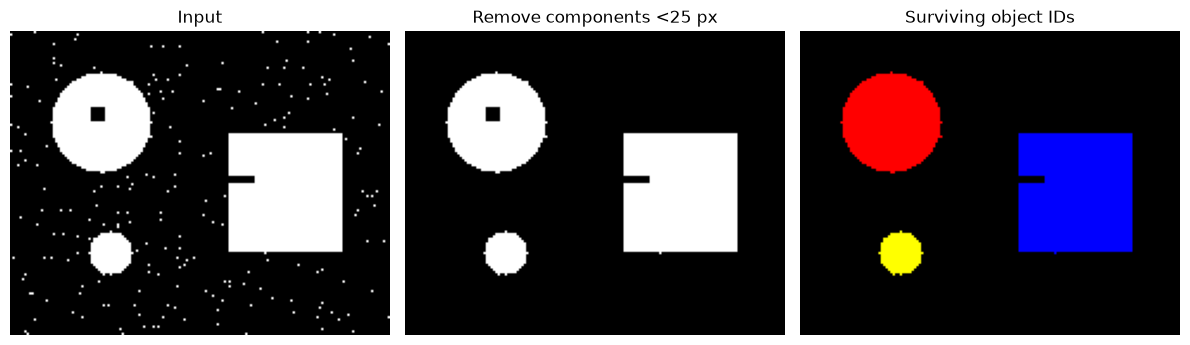

Detected components: 3


In [7]:
def keep_components_at_least(mask, min_area, connectivity=2):
    labels = measure.label(np.asarray(mask, bool), connectivity=connectivity)
    areas = np.bincount(labels.ravel())
    keep = areas >= min_area
    keep[0] = False
    return keep[labels]

area_cleaned = keep_components_at_least(damaged, min_area=25)
final_mask = ndi.binary_fill_holes(area_cleaned)
object_labels = measure.label(final_mask, connectivity=2)
show_grid([damaged, area_cleaned, color.label2rgb(object_labels, bg_label=0)],
          ["Input", "Remove components <25 px", "Surviving object IDs"])
print("Detected components:", object_labels.max())


## 6. Measure the resulting objects

`regionprops_table` converts labeled regions to measurements. Area is in **pixels²** here; bounding boxes use `(min_row, min_col, max_row, max_col)`, with exclusive upper bounds. A centroid is an average position, not necessarily a foreground pixel. Eccentricity approaches 1 for elongated regions.

Counts and areas are measurements of the **predicted mask**, not automatically of the real world.


,label,area,centroid-0,centroid-1,bbox-0,bbox-1,bbox-2,bbox-3,eccentricity,solidity
0,1,1376.0,38.01,38.03,17,17,60,60,0.04,0.96
1,2,2368.0,67.59,115.75,43,92,94,140,0.32,0.98
2,3,255.0,93.01,41.96,84,33,103,52,0.11,0.93


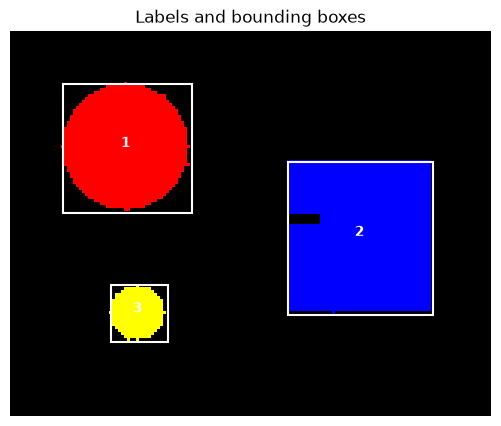

In [8]:
properties = measure.regionprops_table(
    object_labels,
    properties=("label", "area", "centroid", "bbox", "eccentricity", "solidity"),
)
table = pd.DataFrame(properties)
display(table.round(2))

fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(color.label2rgb(object_labels, bg_label=0))
for region in measure.regionprops(object_labels):
    row0, col0, row1, col1 = region.bbox
    ax.add_patch(plt.Rectangle((col0, row0), col1-col0, row1-row0,
                              fill=False, edgecolor="white", linewidth=1.5))
    row, col = region.centroid
    ax.text(col, row, str(region.label), color="white", ha="center", weight="bold")
ax.set_title("Labels and bounding boxes")
ax.axis("off")
plt.show()


## 7. Experiment: small-object removal has a cost

The smaller disk is a genuine object in our construction. Raising an area threshold can make the image look cleaner while reducing recall. Record both pixel overlap and object count; the metrics answer different questions. A merged pair can have good pixel overlap but a wrong count.


,min_area,component_count,foreground_IoU
0,5,3,0.990
1,25,3,0.990
2,400,2,0.928


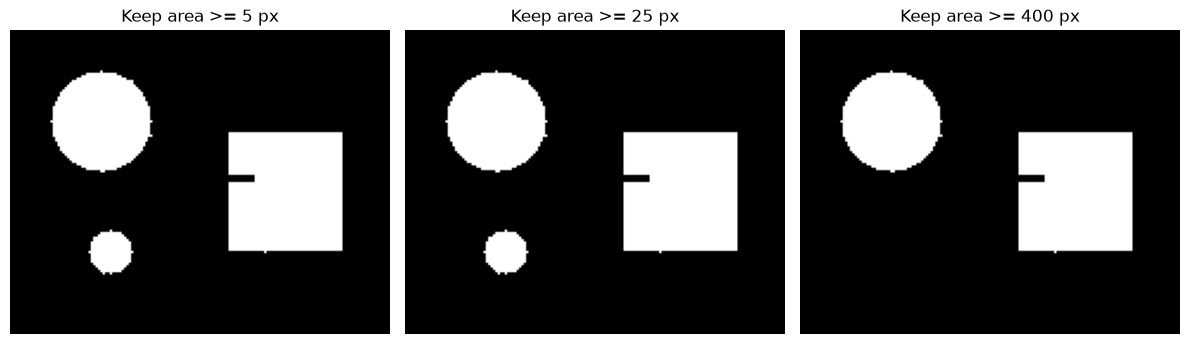

In [9]:
def overlap_iou(target, prediction):
    union = np.logical_or(target, prediction).sum()
    return np.logical_and(target, prediction).sum() / union if union else 1.0

records, masks = [], []
for minimum in (5, 25, 400):
    candidate = ndi.binary_fill_holes(keep_components_at_least(damaged, minimum))
    masks.append(candidate)
    records.append({"min_area": minimum,
                    "component_count": int(measure.label(candidate, connectivity=2).max()),
                    "foreground_IoU": overlap_iou(truth, candidate)})
display(pd.DataFrame(records).round(3))
show_grid(masks, [f"Keep area >= {m} px" for m in (5, 25, 400)])


## 8. Border policy and physical units

An object clipped by the image edge has an incomplete area. Some counting protocols exclude such objects; others keep them with a flag. `clear_border` implements exclusion. Set this policy before comparing experiments.

For square pixels 0.5 mm wide, an area of 100 pixels represents `100 × 0.5² = 25 mm²`. Anisotropic pixels require row-spacing × column-spacing.


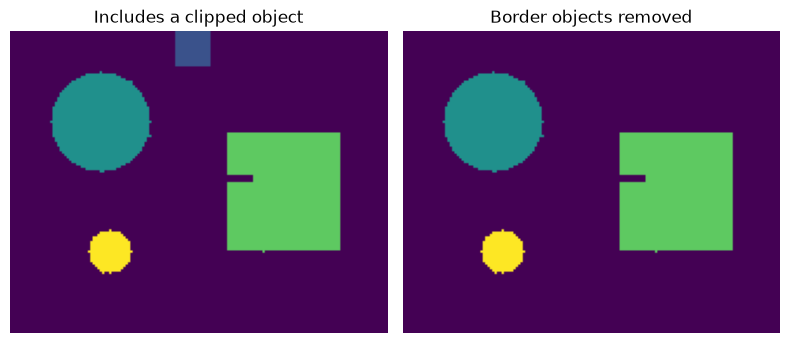

,label,area,area_mm2
0,1,1376.0,344.00
1,2,2368.0,592.00
2,3,255.0,63.75


In [10]:
border_demo = final_mask.copy()
border_demo[0:15, 70:85] = True
border_labels = measure.label(border_demo)
interior_labels = segmentation.clear_border(border_labels)
show_grid([border_labels, interior_labels], ["Includes a clipped object", "Border objects removed"],
          columns=2, cmap="viridis")
pixel_height_mm, pixel_width_mm = 0.5, 0.5
table["area_mm2"] = table["area"] * pixel_height_mm * pixel_width_mm
display(table[["label", "area", "area_mm2"]])


## 9. Exercises — predict before running

**A. Morphology scale.** Compare opening with disk radii 1, 4, and 10 on `truth`. Which real object disappears first?

<details><summary>Worked solution A</summary>

```python
results = [morphology.opening(truth, morphology.disk(r)) for r in (1, 4, 10)]
show_grid(results, ["radius 1", "radius 4", "radius 10"])
```
The radius-9 disk cannot contain a radius-10 footprint, so it disappears. Opening removes structures based on shape and width, not just total area.
</details>


**B. Largest component.** Keep only the largest foreground component, with an explicit empty-mask case. Why is this a questionable default for cell counting?

<details><summary>Worked solution B</summary>

```python
labels = measure.label(final_mask)
sizes = np.bincount(labels.ravel())
sizes[0] = 0
largest = labels == sizes.argmax() if sizes.max() > 0 else np.zeros_like(final_mask)
show_grid([final_mask, largest], ["All objects", "Largest only"], columns=2)
```
It deliberately discards every other object, including valid cells. It fits a one-object task only when that assumption is justified.
</details>


**C. Export measurements.** Save the component table under the project's `outputs` folder, including your pixel calibration. Reopen it and check its row count.

<details><summary>Worked solution C</summary>

```python
destination = PROJECT_ROOT / "outputs" / "03_component_measurements.csv"
destination.parent.mkdir(parents=True, exist_ok=True)
table.to_csv(destination, index=False)
reloaded = pd.read_csv(destination)
assert len(reloaded) == len(table)
print(destination)
```
For a research project, record the image ID, calibration source, units, and processing parameters alongside this table.
</details>


## Common mistakes and completion checklist

- A Boolean mask and an integer label image have different meanings. Relabel a mask before measuring instances.
- Area filtering cannot separate touching objects; they are already one component. Notebook 04 addresses this.
- Filling all holes can erase valid anatomy or ring-shaped structures.
- Repeated cleaning can improve appearance while damaging small-object recall.
- The largest numeric label is a count only when IDs are consecutive; after filtering, use the number of unique nonzero IDs.

- [ ] I can explain all four basic morphological operations.
- [ ] I can explain 4- versus 8-neighbor connectivity.
- [ ] I can draw a bounding box using row/column conventions.
- [ ] I have completed the three exercises and saved one result.
- [ ] I can justify a minimum area and a border policy for a stated task.

**Next:** notebook 04 separates touching foreground regions with markers and watershed.


## Official references

- [scikit-image morphology API](https://scikit-image.org/docs/stable/api/skimage.morphology.html)
- [Measure region properties](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_regionprops.html)
- [Label and region measurement API](https://scikit-image.org/docs/stable/api/skimage.measure.html)
- [SciPy binary hole filling](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.binary_fill_holes.html)

The current scikit-image API (0.26) uses inclusive `max_size` for small-object/hole removal, replacing older size arguments. This notebook implements its stated **keep area ≥ minimum** rule explicitly.
